# Facial Emotion Recognition — FER2013
## Comparing 3 Transfer-Learning Strategies on EfficientNet-B0

**Computer Vision Systems Development — Final Project (SDAIA Academy)**

| | Strategy | What is trained |
|---|---|---|
| 1 | **Feature Extraction** | Only the new last layer (backbone frozen) |
| 2 | **Partial Fine-Tuning** | Last 2 blocks + the new last layer |
| 3 | **Full Fine-Tuning** | The whole network |


<div dir="rtl">

# التعرّف على مشاعر الوجه — FER2013
## مقارنة 3 استراتيجيات للتعلّم بالنقل على نموذج EfficientNet-B0

| | الاستراتيجية | ما يتم تدريبه |
|---|---|---|
| 1 | **استخراج الخصائص** | الطبقة الأخيرة الجديدة فقط (باقي الشبكة مجمّد) |
| 2 | **ضبط دقيق جزئي** | آخر كتلتين + الطبقة الأخيرة |
| 3 | **ضبط دقيق كامل** | الشبكة كاملة |

</div>

---
## 📖 About the Dataset

**Source:** [FER2013 on Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

FER2013 (*Facial Expression Recognition 2013*) was introduced in a Kaggle competition in 2013 as part of the ICML workshop *"Challenges in Representation Learning"*. The faces were collected automatically from Google image search, so they are **real-world faces**: different ages, poses, lighting, glasses, hands covering the face, etc.

| Property | Value |
|---|---|
| Total images | ~35,900 |
| Image size | **48 × 48 pixels** |
| Color | **Grayscale** (1 channel) |
| Classes | **7 emotions** |
| Train / Test | ~28,700 / ~7,200 images |
| Format | `.jpg` files in one folder per class |

**The 7 classes:** `angry` 😠 · `disgust` 🤢 · `fear` 😨 · `happy` 😄 · `neutral` 😐 · `sad` 😢 · `surprise` 😲

**Folder structure:**
```
fer2013/
├── train/
│   ├── angry/     ├── disgust/   ├── fear/   ├── happy/
│   ├── neutral/   ├── sad/       └── surprise/
└── test/
    └── (same 7 folders)
```

### ⚠️ Things to know before you start
1. **The classes are imbalanced** — `happy` has ~7,000 training images while `disgust` has only ~400. A model can get "good" accuracy just by ignoring the rare classes, so look at **per-class** results, not only overall accuracy.
2. **The task is hard** — the images are small and blurry, and some emotions look alike (fear vs. surprise, sad vs. neutral). Human accuracy on this dataset is estimated at only **~65%**, so don't expect 95%!
3. **There is no validation set** — we will create one from the training set.
4. **Some labels are noisy** — a few images are mislabeled or are not faces at all.

<div dir="rtl">

---
## 📖 نبذة عن البيانات

**المصدر:** [FER2013 على Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

بيانات FER2013 (*التعرّف على تعابير الوجه 2013*) نُشرت في مسابقة على Kaggle عام 2013 ضمن ورشة ICML بعنوان *"تحديات تعلّم التمثيلات"*. جُمعت الوجوه تلقائياً من بحث صور Google، لذلك هي **وجوه من الواقع**: أعمار مختلفة، وضعيات مختلفة، إضاءة متفاوتة، نظارات، أيدٍ تغطي الوجه... إلخ.

| الخاصية | القيمة |
|---|---|
| عدد الصور الكلي | حوالي 35,900 |
| حجم الصورة | **48 × 48 بكسل** |
| الألوان | **رمادية (Grayscale)** — قناة واحدة |
| عدد الأصناف | **7 مشاعر** |
| تدريب / اختبار | حوالي 28,700 / 7,200 صورة |
| الصيغة | ملفات `.jpg` في مجلد لكل صنف |

**الأصناف السبعة:** `angry` غضب 😠 · `disgust` اشمئزاز 🤢 · `fear` خوف 😨 · `happy` سعادة 😄 · `neutral` محايد 😐 · `sad` حزن 😢 · `surprise` مفاجأة 😲

### ⚠️ أمور مهمة قبل البدء
1. **الأصناف غير متوازنة** — صنف `happy` فيه حوالي 7,000 صورة تدريب بينما `disgust` فيه حوالي 400 فقط. النموذج قد يحصل على دقة "جيدة" وهو يتجاهل الأصناف النادرة، لذلك انظر إلى النتائج **لكل صنف** وليس الدقة الكلية فقط.
2. **المهمة صعبة** — الصور صغيرة وغير واضحة، وبعض المشاعر متشابهة (الخوف والمفاجأة، الحزن والمحايد). دقة الإنسان على هذه البيانات تُقدّر بحوالي **65%** فقط، فلا تتوقع 95%!
3. **لا توجد بيانات تحقق (validation)** — سننشئها من بيانات التدريب.
4. **بعض التسميات فيها أخطاء** — بعض الصور مصنّفة خطأ أو ليست وجوهاً أصلاً.

</div>

---
## 🎯 Problem Definition

**Problem:** Recognise the emotion shown on a human face from a single image.

**Purpose:** An emotion-recognition system can support e-learning platforms (detecting confused or bored students), customer-experience analysis, driver-fatigue / wellbeing monitoring, and human–robot interaction.

**Input → Output:** a face image → one of **7 emotions** (`angry, disgust, fear, happy, neutral, sad, surprise`) + a confidence score for each emotion.

**Computer-vision task:** image **classification** (multi-class, 7 classes).

### Our approach
Instead of building one model, we take **one pretrained CNN (EfficientNet-B0, trained on ImageNet)** and adapt it to faces in **three different ways**, then compare them on **accuracy, loss and training time** (plus per-class F1, because the classes are imbalanced).

To keep the comparison **fair**, all three use the same data split, the same preprocessing/augmentation, the same number of epochs, the same optimizer and the same loss — the **only** difference is *how much of the network we allow to train*.

### Pipeline
`Kaggle data → split (train/val/test) → preprocessing & augmentation → EfficientNet-B0 × 3 strategies → evaluation & comparison → best model → face detection + prediction → ONNX export + INT8 quantization → demo app`


<div dir="rtl">

## 🎯 تعريف المشكلة

**المشكلة:** التعرّف على الشعور الظاهر على وجه الإنسان من صورة واحدة.

**الهدف من النظام:** يمكن أن يخدم منصات التعليم الإلكتروني (رصد الطالب المرتبك أو الملول)، وتحليل تجربة العملاء، ومراقبة إرهاق السائقين، والتفاعل بين الإنسان والروبوت.

**المدخل ← المخرج:** صورة وجه ← واحد من **7 مشاعر** + نسبة ثقة لكل شعور.

**نوع المهمة:** **تصنيف صور** (7 أصناف).

### طريقتنا
بدلاً من نموذج واحد، نأخذ **شبكة CNN واحدة مدرّبة مسبقاً (EfficientNet-B0 على ImageNet)** ونكيّفها مع الوجوه **بثلاث طرق**، ثم نقارن بينها في **الدقة والخسارة وزمن التدريب** (ومعها F1 لكل صنف بسبب عدم توازن الأصناف).

لتكون المقارنة **عادلة**: نفس تقسيم البيانات، ونفس المعالجة والتوسيع، ونفس عدد الدورات، ونفس المُحسِّن ودالة الخسارة — والفرق **الوحيد** هو *مقدار ما نسمح بتدريبه من الشبكة*.

</div>

---
## 1. Setup
> In Colab, enable the GPU: **Runtime → Change runtime type → T4 GPU**

<div dir="rtl">

## 1. الإعداد
> في Colab فعّل الـ GPU من: **Runtime → Change runtime type → T4 GPU**

</div>

In [1]:
# Install kagglehub (used to download datasets from Kaggle)
# تثبيت مكتبة kagglehub لتحميل البيانات من Kaggle
!pip install -q kagglehub

In [2]:
# Extra libraries for deployment (ONNX export + quantization) and the demo app
# مكتبات إضافية للنشر (تصدير ONNX والتكميم) وتطبيق العرض
!pip install -q onnx onnxruntime onnxscript gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 18.5 MB/s eta 0:00:00


In [3]:
import os
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split

# ---- Reproducibility: same random results every run ----
# ---- تثبيت العشوائية: نفس النتائج في كل تشغيل ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use the GPU if available, otherwise the CPU
# استخدم الـ GPU إن وُجد، وإلا الـ CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### Project configuration
All the settings of the experiment in one place. Every strategy uses **exactly the same** values.


<div dir="rtl">

### إعدادات المشروع
كل إعدادات التجربة في مكان واحد، وكل الاستراتيجيات تستخدم **نفس القيم تماماً**.

</div>

In [4]:
import time, json, copy, shutil
import pandas as pd
import torch.nn as nn
from torchvision import models
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, classification_report, confusion_matrix

# ---- Experiment settings / إعدادات التجربة ----
IMG_SIZE      = 224      # EfficientNet-B0 was trained on 224x224 images / الحجم الذي تدرّب عليه النموذج
BATCH_SIZE    = 64
NUM_EPOCHS    = 10       # same for all 3 strategies / نفس العدد للاستراتيجيات الثلاث
LR_HEAD       = 1e-3     # learning rate for the new last layer / معدل التعلّم للطبقة الجديدة
LR_BACKBONE   = 1e-4     # smaller LR for pretrained layers we unfreeze / معدل أصغر للطبقات المدرّبة مسبقاً
WEIGHT_DECAY  = 1e-4
VAL_SPLIT     = 0.15     # 15% of train becomes validation / 15% من التدريب تصبح بيانات تحقق
NUM_WORKERS   = 2
USE_PRETRAINED = True    # ImageNet weights / أوزان ImageNet
USE_AMP       = device.type == "cuda"   # mixed precision = faster training on GPU / تدريب أسرع على الـ GPU
FORCE_RETRAIN = False    # if a saved model exists, reuse it (useful if Colab disconnects)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ---- Output folders / مجلدات المخرجات ----
OUT_DIR = "fer_project_outputs"
MODELS_DIR, FIG_DIR = f"{OUT_DIR}/models", f"{OUT_DIR}/figures"
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
print("Outputs will be saved in:", os.path.abspath(OUT_DIR))

Outputs will be saved in: /content/fer_project_outputs


## 2. Download the Data
We use `kagglehub` to download the dataset directly from Kaggle.
> If you get an authentication error: in Colab open 🔑 **Secrets** and add `KAGGLE_USERNAME` and `KAGGLE_KEY` (from Kaggle → Settings → API → Create New Token).

<div dir="rtl">

## 2. تحميل البيانات
نستخدم `kagglehub` لتحميل البيانات مباشرة من Kaggle.
> إذا ظهر خطأ في الصلاحيات: من Colab افتح 🔑 **Secrets** وأضف `KAGGLE_USERNAME` و `KAGGLE_KEY` (من Kaggle ← Settings ← API ← Create New Token).

</div>

In [5]:
import kagglehub

# Download the dataset (it is cached, so running again is instant)
# تحميل البيانات (تُحفظ مؤقتاً، فإعادة التشغيل تكون فورية)
path = kagglehub.dataset_download("msambare/fer2013")
print("Downloaded to:", path)

# Locate the train/ and test/ folders
# تحديد مسار مجلدي التدريب والاختبار
TRAIN_DIR = os.path.join(path, "train")
TEST_DIR  = os.path.join(path, "test")
print("Train folder:", TRAIN_DIR, "| exists:", os.path.isdir(TRAIN_DIR))
print("Test folder: ", TEST_DIR,  "| exists:", os.path.isdir(TEST_DIR))
print("Class folders:", sorted(os.listdir(TRAIN_DIR)))

Using Colab cache for faster access to the 'fer2013' dataset.
Downloaded to: /kaggle/input/fer2013
Train folder: /kaggle/input/fer2013/train | exists: True
Test folder:  /kaggle/input/fer2013/test | exists: True
Class folders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 3. Explore the Data

<div dir="rtl">

## 3. استكشاف البيانات

</div>

In [6]:
# ImageFolder reads a "one folder per class" structure:
# the folder name becomes the class name, and each image gets that label.
# ImageFolder يقرأ البيانات المنظّمة بمجلد لكل صنف:
# اسم المجلد يصبح اسم الصنف، وكل صورة تأخذ تسمية مجلدها.
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_test  = datasets.ImageFolder(TEST_DIR)

CLASS_NAMES = raw_train.classes          # ['angry', 'disgust', 'fear', ...]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", dict(enumerate(CLASS_NAMES)))
print("Train images:", len(raw_train))
print("Test images: ", len(raw_test))

# Check the size and mode of one image (L = grayscale)
# فحص حجم ونوع صورة واحدة (L تعني رمادية)
img, label = raw_train[0]
print("Image size:", img.size, "| mode:", img.mode, "| label:", CLASS_NAMES[label])

Classes: {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}
Train images: 28709
Test images:  7178
Image size: (48, 48) | mode: RGB | label: angry


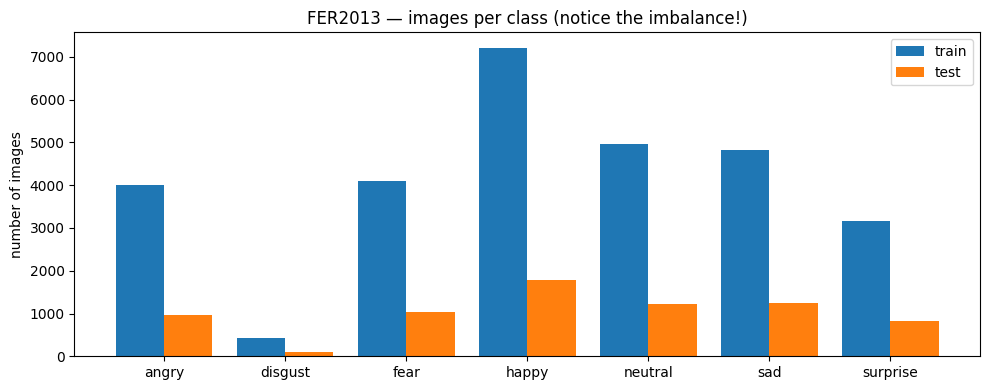

angry      train:  3995   test:   958
disgust    train:   436   test:   111
fear       train:  4097   test:  1024
happy      train:  7215   test:  1774
neutral    train:  4965   test:  1233
sad        train:  4830   test:  1247
surprise   train:  3171   test:   831


In [7]:
# ---- Class distribution: how many images per emotion? ----
# ---- توزيع الأصناف: كم صورة لكل شعور؟ ----
train_counts = Counter(raw_train.targets)
test_counts  = Counter(raw_test.targets)

x = np.arange(NUM_CLASSES)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, [train_counts[i] for i in range(NUM_CLASSES)], width=0.4, label="train")
plt.bar(x + 0.2, [test_counts[i]  for i in range(NUM_CLASSES)], width=0.4, label="test")
plt.xticks(x, CLASS_NAMES)
plt.ylabel("number of images")
plt.title("FER2013 — images per class (notice the imbalance!)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_class_distribution.png", dpi=120)
plt.show()

for i, name in enumerate(CLASS_NAMES):
    print(f"{name:<10} train: {train_counts[i]:>5}   test: {test_counts[i]:>5}")

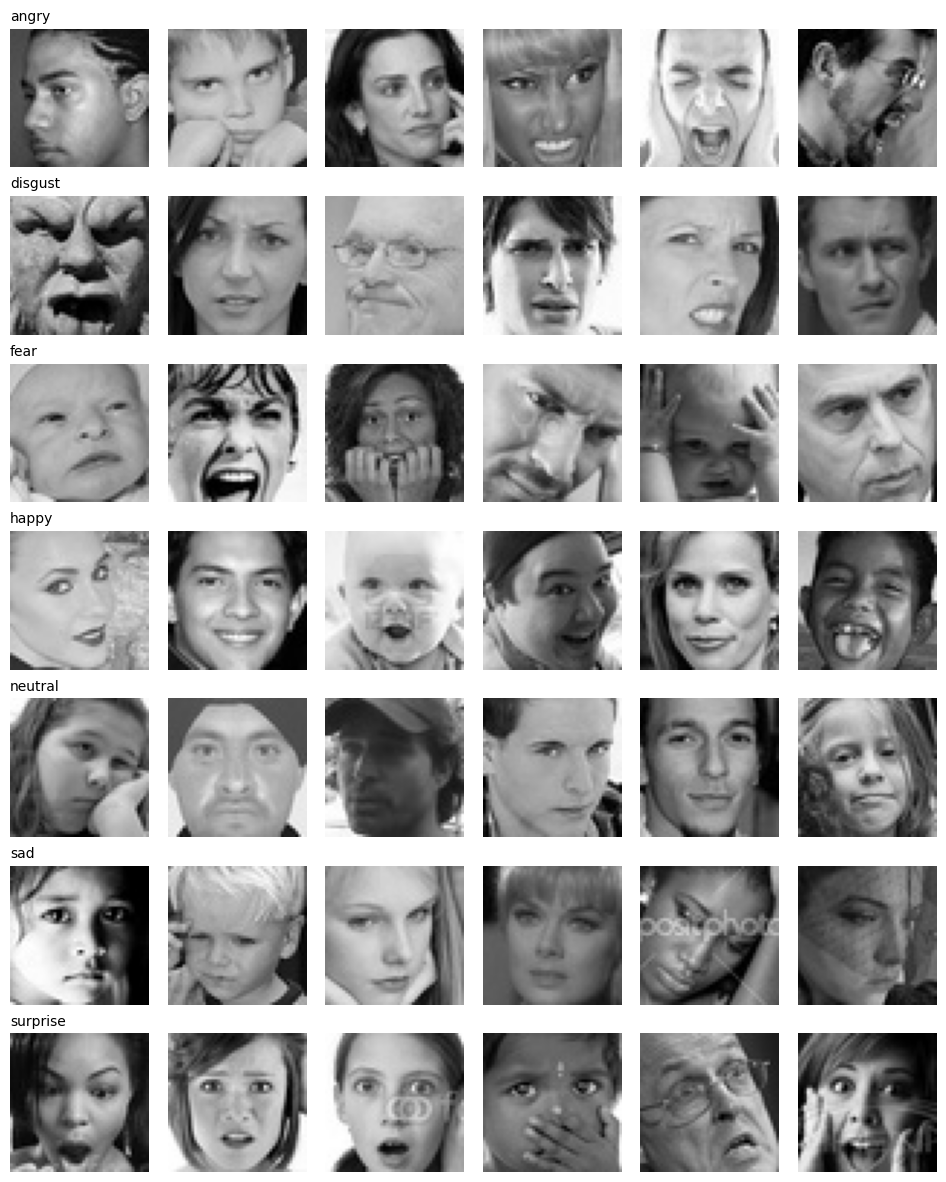

In [8]:
# ---- Show random examples from each class ----
# ---- عرض أمثلة عشوائية من كل صنف ----
N_PER_CLASS = 6
train_targets = np.array(raw_train.targets)

fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(N_PER_CLASS * 1.6, NUM_CLASSES * 1.7))
for c in range(NUM_CLASSES):
    # pick random image indices that belong to class c
    # اختيار صور عشوائية تنتمي للصنف c
    idxs = np.random.choice(np.where(train_targets == c)[0], N_PER_CLASS, replace=False)
    for j, idx in enumerate(idxs):
        img, _ = raw_train[idx]
        axes[c, j].imshow(img, cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_samples_per_class.png", dpi=120)
plt.show()

---
## 4. Preprocessing, Augmentation & Data Split

**Preprocessing** (all images):
- `Grayscale(3)` — FER2013 is grayscale, but EfficientNet expects **3 channels**, so we copy the gray channel 3 times.
- `Resize(224)` — enlarge 48×48 → 224×224, the size the pretrained model was trained on.
- `Normalize` with the **ImageNet mean/std** — the pretrained model must see numbers in the same range it learned on.

**Augmentation** (training images only — creates "new" variations so the model generalises instead of memorising):
- `RandomHorizontalFlip` — a smiling face mirrored is still smiling.
- `RandomAffine` — small rotation (±10°), shift and zoom, like a slightly tilted head.
- `ColorJitter` — brightness/contrast changes, like different lighting.

**Split:** the dataset has no validation set, so we take **15 % of train** (stratified = same class proportions) as validation. The **test set is never used for training or for choosing models** — only for the final evaluation.


<div dir="rtl">

## 4. المعالجة المسبقة والتوسيع وتقسيم البيانات

**المعالجة المسبقة** (لكل الصور):
- `Grayscale(3)` — الصور رمادية بقناة واحدة، والنموذج يتوقع **3 قنوات**، فننسخ القناة الرمادية 3 مرات.
- `Resize(224)` — تكبير 48×48 إلى 224×224، وهو الحجم الذي تدرّب عليه النموذج.
- `Normalize` بمتوسط وانحراف **ImageNet** — ليرى النموذج الأرقام في نفس النطاق الذي تعلّم عليه.

**التوسيع (Augmentation)** (لصور التدريب فقط — ينشئ تنويعات جديدة حتى يتعلّم النموذج بدلاً من أن يحفظ):
- قلب أفقي عشوائي — الوجه المبتسم معكوساً يبقى مبتسماً.
- دوران بسيط (±10°) وإزاحة وتقريب — مثل ميلان الرأس.
- تغيير السطوع والتباين — مثل اختلاف الإضاءة.

**التقسيم:** لا توجد بيانات تحقق، فنأخذ **15% من التدريب** (بنفس نسب الأصناف) كبيانات تحقق. **بيانات الاختبار لا تُستخدم أبداً في التدريب أو اختيار النموذج** — فقط للتقييم النهائي.

</div>

In [9]:
# Augmentations are applied on the small 48x48 image first (cheap), then we resize.
# نطبّق التوسيع على الصورة الصغيرة أولاً (أسرع)، ثم نكبّرها.
train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation / test: NO random augmentation — same image gives the same result every time
# التحقق والاختبار: بدون توسيع عشوائي
eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# ---- Stratified train / validation split ----
# ---- تقسيم التدريب/التحقق مع الحفاظ على نسب الأصناف ----
all_idx = np.arange(len(raw_train))
train_idx, val_idx = train_test_split(all_idx, test_size=VAL_SPLIT,
                                      stratify=raw_train.targets, random_state=SEED)

# Two views of the same folder: one with augmentation (train), one without (val)
train_ds = Subset(datasets.ImageFolder(TRAIN_DIR, transform=train_tf), train_idx)
val_ds   = Subset(datasets.ImageFolder(TRAIN_DIR, transform=eval_tf),  val_idx)
test_ds  = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                   pin_memory=(device.type == "cuda"), persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), **loader_args)
val_loader   = DataLoader(val_ds,  shuffle=False, **loader_args)
test_loader  = DataLoader(test_ds, shuffle=False, **loader_args)

print(f"Train: {len(train_ds):,} | Validation: {len(val_ds):,} | Test: {len(test_ds):,}")

Train: 24,402 | Validation: 4,307 | Test: 7,178


Batch shape: (64, 3, 224, 224)


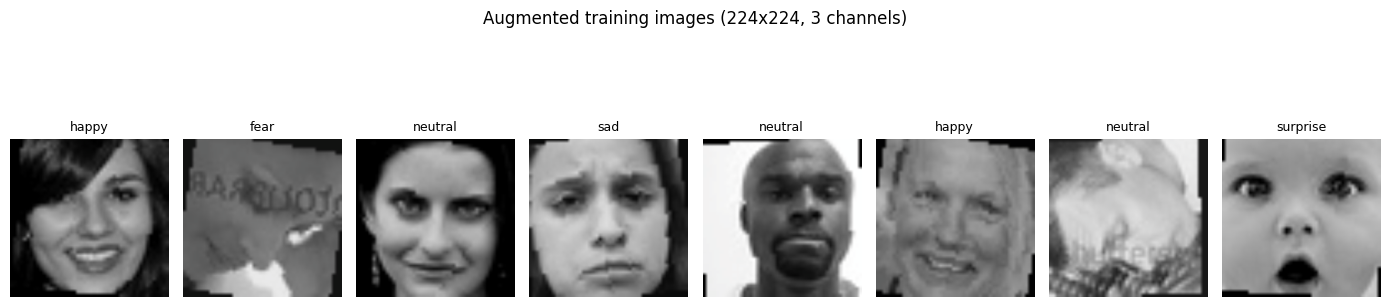

In [10]:
# ---- Look at what the model will actually see (augmented training images) ----
# ---- نشاهد ما سيراه النموذج فعلاً (صور تدريب بعد التوسيع) ----
def denorm(t):
    img = t.permute(1, 2, 0).numpy() * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)

imgs, lbls = next(iter(train_loader))
print("Batch shape:", tuple(imgs.shape))   # [batch, 3 channels, 224, 224]
plt.figure(figsize=(14, 4))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(denorm(imgs[i]))
    plt.title(CLASS_NAMES[lbls[i]], fontsize=9)
    plt.axis("off")
plt.suptitle("Augmented training images (224x224, 3 channels)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_augmented_batch.png", dpi=120)
plt.show()

### Handling class imbalance
`disgust` has ~16× fewer images than `happy`. We give the loss function **class weights** so mistakes on rare classes cost more.
We use a *softened* weight (square root of the inverse frequency) so rare classes get more attention without the model over-predicting them.


<div dir="rtl">

### معالجة عدم توازن الأصناف
صنف `disgust` أقل من `happy` بحوالي 16 مرة. لذلك نعطي دالة الخسارة **أوزاناً للأصناف** بحيث يكون الخطأ في الصنف النادر أغلى.
نستخدم وزناً *مُلطَّفاً* (الجذر التربيعي لمقلوب التكرار) حتى ينتبه النموذج للأصناف النادرة دون أن يبالغ في توقّعها.

</div>

In [11]:
train_labels = np.array(raw_train.targets)[train_idx]
counts = np.bincount(train_labels, minlength=NUM_CLASSES)
w = np.sqrt(counts.max() / counts)
class_weights = torch.tensor(w / w.mean(), dtype=torch.float32)

print(pd.DataFrame({"class": CLASS_NAMES, "train images": counts,
                    "loss weight": class_weights.numpy().round(2)}).to_string(index=False))

# The same loss function for all 3 strategies / نفس دالة الخسارة للاستراتيجيات الثلاث
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

   class  train images  loss weight
   angry          3396         0.81
 disgust           371         2.44
    fear          3482         0.80
   happy          6133         0.60
 neutral          4220         0.72
     sad          4105         0.73
surprise          2695         0.90


---
## 5. The Model: EfficientNet-B0 + 3 Transfer-Learning Strategies

**EfficientNet-B0** (Google, 2019) is a CNN pretrained on **ImageNet** (1.4 M images, 1000 classes). It has ~4 M parameters and is built from **MBConv** blocks (depthwise convolutions + squeeze-and-excitation). Its structure in PyTorch:

```
model.features[0 … 8]   ← 9 feature blocks (edges → textures → shapes → high-level patterns)
model.avgpool           ← global average pooling → a vector of 1280 numbers
model.classifier[1]     ← Linear(1280 → 1000 ImageNet classes)   ⟵ we replace this with Linear(1280 → 7)
```

| Strategy | Frozen | Trainable | Idea |
|---|---|---|---|
| **1. Feature Extraction** | all of `features` | new `classifier` only | use ImageNet features as they are |
| **2. Partial Fine-Tuning** | `features[0…6]` | `features[7:]` (**last 2 blocks**) + `classifier` | keep generic early layers, adapt high-level layers to faces |
| **3. Full Fine-Tuning** | nothing | everything | the pretrained weights are only a starting point |

Learning rates: the new layer starts from random values → **LR = 1e-3**. Pretrained layers are already good → smaller **LR = 1e-4** so we don't destroy what they learned.


<div dir="rtl">

## 5. النموذج: EfficientNet-B0 + ثلاث استراتيجيات للتعلّم بالنقل

**EfficientNet-B0** (من Google عام 2019) شبكة CNN مدرّبة مسبقاً على **ImageNet** (1.4 مليون صورة و1000 صنف)، فيها حوالي 4 ملايين معامل، ومبنية من كتل **MBConv**.

- `model.features[0…8]` ← 9 كتل لاستخراج الخصائص (حواف ← أنسجة ← أشكال ← أنماط عالية المستوى)
- `model.classifier[1]` ← الطبقة الأخيرة (1280 ← 1000 صنف) **نستبدلها** بطبقة (1280 ← 7 مشاعر)

| الاستراتيجية | المجمَّد | ما يُدرَّب | الفكرة |
|---|---|---|---|
| **1. استخراج الخصائص** | كل `features` | الطبقة الأخيرة فقط | نستخدم خصائص ImageNet كما هي |
| **2. ضبط دقيق جزئي** | `features[0…6]` | **آخر كتلتين** + الطبقة الأخيرة | نبقي الطبقات العامة ونكيّف الطبقات العليا مع الوجوه |
| **3. ضبط دقيق كامل** | لا شيء | الشبكة كلها | الأوزان المسبقة مجرد نقطة بداية |

معدل التعلّم: الطبقة الجديدة تبدأ عشوائية ← **1e-3**، والطبقات المدرّبة مسبقاً جيدة أصلاً ← **1e-4** أصغر حتى لا نفسد ما تعلّمته.

</div>

In [12]:
STRATEGIES = {
    "feature_extraction": "1. Feature Extraction (last layer only)",
    "partial_finetune":   "2. Partial Fine-Tuning (last 2 blocks + last layer)",
    "full_finetune":      "3. Full Fine-Tuning (whole network)",
}

def build_model(strategy):
    """Load pretrained EfficientNet-B0 and set which layers are trainable.
    نحمّل النموذج المدرّب مسبقاً ونحدّد الطبقات القابلة للتدريب."""
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if USE_PRETRAINED else None
    model = models.efficientnet_b0(weights=weights)

    # Step 1: freeze everything / نجمّد كل شيء
    for p in model.parameters():
        p.requires_grad = False

    # Step 2: unfreeze according to the strategy / نفك التجميد حسب الاستراتيجية
    if strategy == "partial_finetune":
        for p in model.features[7:].parameters():      # last 2 feature blocks / آخر كتلتين
            p.requires_grad = True
    elif strategy == "full_finetune":
        for p in model.parameters():                   # everything / كل الشبكة
            p.requires_grad = True

    # Step 3: replace the last layer: 1000 ImageNet classes -> 7 emotions (trainable by default)
    # نستبدل الطبقة الأخيرة: 1000 صنف ← 7 مشاعر (قابلة للتدريب تلقائياً)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    return model.to(device)


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total


for key, name in STRATEGIES.items():
    t, n = count_params(build_model(key))
    print(f"{name:<55} trainable: {t:>9,} / {n:,}  ({100 * t / n:5.2f}%)")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s]


1. Feature Extraction (last layer only)                 trainable:     8,967 / 4,016,515  ( 0.22%)
2. Partial Fine-Tuning (last 2 blocks + last layer)     trainable: 1,138,359 / 4,016,515  (28.34%)
3. Full Fine-Tuning (whole network)                     trainable: 4,016,515 / 4,016,515  (100.00%)


### Training & evaluation functions
One shared training loop for all strategies:
- **AdamW** optimizer with two learning rates (new layer / pretrained layers) and a **cosine** schedule that slowly lowers the LR.
- **Mixed precision (AMP)** on GPU — same results, faster training.
- After every epoch we check the **validation** set and keep the weights of the **best epoch** (highest validation accuracy).
- We measure the **training time** of each strategy.


<div dir="rtl">

### دوال التدريب والتقييم
حلقة تدريب واحدة مشتركة لكل الاستراتيجيات:
- المُحسِّن **AdamW** بمعدلَي تعلّم (للطبقة الجديدة وللطبقات المسبقة) مع جدول **cosine** يخفّض المعدل تدريجياً.
- **الدقة المختلطة (AMP)** على الـ GPU — نفس النتائج وتدريب أسرع.
- بعد كل دورة نقيس على بيانات **التحقق** ونحتفظ بأوزان **أفضل دورة**.
- نقيس **زمن التدريب** لكل استراتيجية.

</div>

In [13]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    """One pass over the data. Trains if an optimizer is given, otherwise only evaluates.
    مرور واحد على البيانات: تدريب إذا أُعطي مُحسِّن، وإلا تقييم فقط."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    all_probs, all_labels = [], []

    with torch.set_grad_enabled(training):
        for images, labels in tqdm(loader, leave=False, desc="train" if training else "eval"):
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits.float(), labels)

            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            n += labels.size(0)
            if not training:
                all_probs.append(torch.softmax(logits.float(), 1).cpu())
                all_labels.append(labels.cpu())

    out = {"loss": total_loss / n, "acc": 100 * correct / n}
    if not training:
        out["probs"] = torch.cat(all_probs).numpy()
        out["labels"] = torch.cat(all_labels).numpy()
        out["preds"] = out["probs"].argmax(1)
        out["macro_f1"] = 100 * f1_score(out["labels"], out["preds"], average="macro")
    return out


def run_experiment(strategy):
    """Build -> train for NUM_EPOCHS -> keep the best epoch -> save."""
    ckpt, hist_file = f"{MODELS_DIR}/{strategy}.pth", f"{MODELS_DIR}/{strategy}_history.json"
    model = build_model(strategy)
    trainable, total = count_params(model)

    # Reuse a finished run (e.g. after a Colab disconnect) / إعادة استخدام تدريب سابق محفوظ
    if os.path.exists(ckpt) and os.path.exists(hist_file) and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=device))
        info = json.load(open(hist_file))
        print(f"Loaded saved model for {STRATEGIES[strategy]} (set FORCE_RETRAIN=True to retrain)")
        return model, info

    head = list(model.classifier.parameters())
    backbone = [p for n_, p in model.named_parameters()
                if p.requires_grad and not n_.startswith("classifier")]
    groups = [{"params": head, "lr": LR_HEAD}]
    if backbone:
        groups.append({"params": backbone, "lr": LR_BACKBONE})
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "epoch_time"]}
    best_acc, best_state, best_epoch = -1, None, 0
    print(f"\n=== {STRATEGIES[strategy]} | trainable params: {trainable:,} / {total:,} ===")
    start = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        t0 = time.time()
        tr = run_epoch(model, train_loader, optimizer, scaler)
        va = run_epoch(model, val_loader)
        scheduler.step()
        if device.type == "cuda":
            torch.cuda.synchronize()
        ep_time = time.time() - t0

        for k, v in [("train_loss", tr["loss"]), ("train_acc", tr["acc"]), ("val_loss", va["loss"]),
                     ("val_acc", va["acc"]), ("val_macro_f1", va["macro_f1"]), ("epoch_time", ep_time)]:
            history[k].append(v)
        if va["acc"] > best_acc:
            best_acc, best_epoch = va["acc"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch:2d}/{NUM_EPOCHS} | train loss {tr['loss']:.4f} acc {tr['acc']:5.2f}% "
              f"| val loss {va['loss']:.4f} acc {va['acc']:5.2f}% F1 {va['macro_f1']:5.2f}% | {ep_time:5.1f}s")

    train_time = time.time() - start
    model.load_state_dict(best_state)          # keep the best epoch / نحتفظ بأفضل دورة
    torch.save(best_state, ckpt)
    info = {"strategy": strategy, "name": STRATEGIES[strategy], "trainable_params": trainable,
            "total_params": total, "train_time_sec": train_time, "best_epoch": best_epoch,
            "best_val_acc": best_acc, "history": history}
    json.dump(info, open(hist_file, "w"), indent=2)
    print(f"Done in {train_time / 60:.1f} min | best epoch {best_epoch} (val acc {best_acc:.2f}%)")
    return model, info


def plot_history(info):
    h, ep = info["history"], range(1, len(info["history"]["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, h["train_loss"], "o-", label="train"); ax[0].plot(ep, h["val_loss"], "o-", label="validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], "o-", label="train"); ax[1].plot(ep, h["val_acc"], "o-", label="validation")
    ax[1].set_title("Accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    fig.suptitle(info["name"])
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/curves_{info['strategy']}.png", dpi=120)
    plt.show()


trained = {}   # strategy -> (model, info)

---
## 6. Strategy 1 — Feature Extraction (freeze everything, train only the last layer)
The pretrained network is used as a **fixed feature extractor**; only the new `Linear(1280 → 7)` layer learns (~9 K parameters).
⚡ fastest · 🛡️ lowest overfitting risk · ⚠️ ImageNet features were learned on objects, not facial expressions, so accuracy may be limited.


<div dir="rtl">

## 6. الاستراتيجية 1 — استخراج الخصائص (تجميد الشبكة وتدريب الطبقة الأخيرة فقط)
نستخدم الشبكة المدرّبة مسبقاً **كمستخرج خصائص ثابت**، ولا يتعلّم إلا الطبقة الجديدة (حوالي 9 آلاف معامل).
⚡ الأسرع · 🛡️ أقل خطر للحفظ (Overfitting) · ⚠️ خصائص ImageNet تعلّمت على أشياء وليس تعابير وجوه، فقد تكون الدقة محدودة.

</div>


=== 1. Feature Extraction (last layer only) | trainable params: 8,967 / 4,016,515 ===


train:   0%|          | 0/382 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch  1/10 | train loss 1.7193 acc 34.25% | val loss 1.6204 acc 38.75% F1 30.44% | 127.1s


train:   0%|          | 0/382 [00:00<?, ?it/s]

...

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch  9/10 | train loss 1.5908 acc 40.60% | val loss 1.5350 acc 43.35% F1 37.00% |  92.0s


train:   0%|          | 0/382 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 10/10 | train loss 1.5834 acc 40.51% | val loss 1.5339 acc 43.26% F1 36.29% |  94.0s
Done in 15.7 min | best epoch 9 (val acc 43.35%)


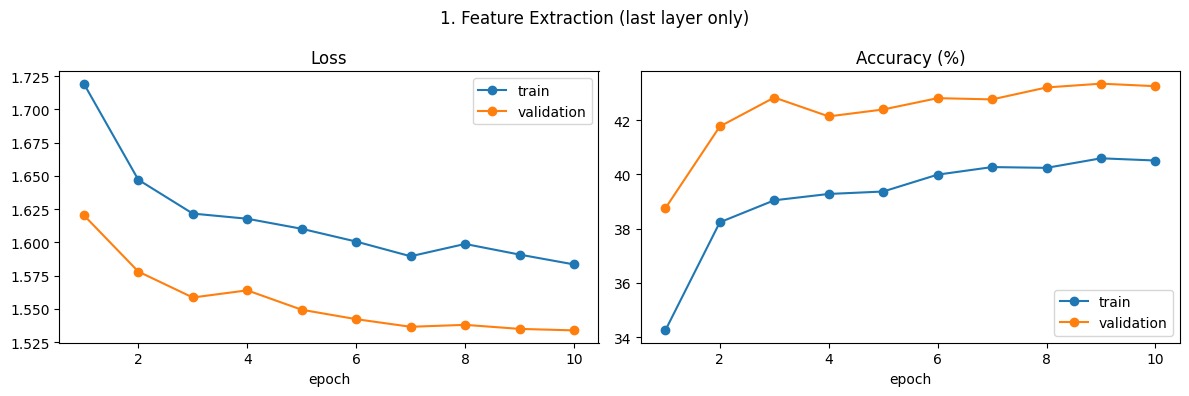

In [14]:
trained["feature_extraction"] = run_experiment("feature_extraction")
plot_history(trained["feature_extraction"][1])

---
## 7. Strategy 2 — Partial Fine-Tuning (unfreeze the last 2 blocks)
Early blocks (edges, textures) stay frozen because they are useful for any image. The **last 2 blocks** (`features[7]`, `features[8]`) + the new layer are trained so the high-level features adapt to faces (~1.1 M parameters, ~28 %).
⚖️ middle ground in speed and accuracy.


<div dir="rtl">

## 7. الاستراتيجية 2 — ضبط دقيق جزئي (فك تجميد آخر كتلتين)
الكتل الأولى (الحواف والأنسجة) تبقى مجمّدة لأنها مفيدة لأي صورة، ونُدرّب **آخر كتلتين** مع الطبقة الجديدة لتتكيّف الخصائص العليا مع الوجوه (حوالي 1.1 مليون معامل، 28%).
⚖️ حل وسط في السرعة والدقة.

</div>


=== 2. Partial Fine-Tuning (last 2 blocks + last layer) | trainable params: 1,138,359 / 4,016,515 ===


train:   0%|          | 0/382 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch  1/10 | train loss 1.6365 acc 38.48% | val loss 1.4583 acc 46.20% F1 38.56% |  94.8s


train:   0%|          | 0/382 [00:00<?, ?it/s]

...

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch  9/10 | train loss 1.2581 acc 54.04% | val loss 1.2210 acc 55.72% F1 49.68% |  90.9s


train:   0%|          | 0/382 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 10/10 | train loss 1.2536 acc 54.09% | val loss 1.2240 acc 55.56% F1 49.34% |  91.3s
Done in 15.4 min | best epoch 8 (val acc 55.82%)


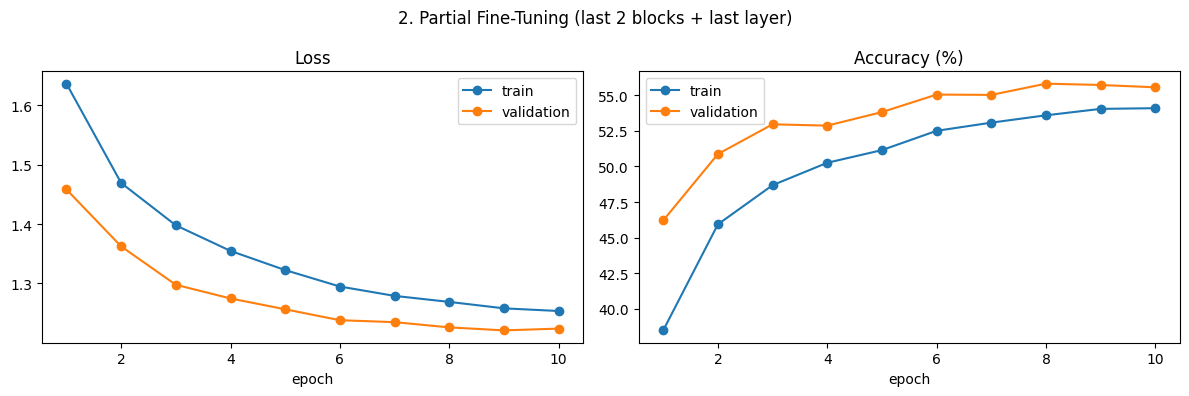

In [15]:
trained["partial_finetune"] = run_experiment("partial_finetune")
plot_history(trained["partial_finetune"][1])

---
## 8. Strategy 3 — Full Fine-Tuning (train the whole network)
Every layer is trainable (~4 M parameters). Pretrained weights are just a good starting point.
🎯 highest potential accuracy (we have ~24 K training images) · ⏳ slowest · 📉 higher overfitting risk.


<div dir="rtl">

## 8. الاستراتيجية 3 — ضبط دقيق كامل (تدريب الشبكة كلها)
كل الطبقات قابلة للتدريب (حوالي 4 ملايين معامل)، والأوزان المسبقة مجرد نقطة بداية جيدة.
🎯 أعلى دقة متوقعة (لدينا حوالي 24 ألف صورة تدريب) · ⏳ الأبطأ · 📉 خطر أعلى للحفظ.

</div>


=== 3. Full Fine-Tuning (whole network) | trainable params: 4,016,515 / 4,016,515 ===


train:   0%|          | 0/382 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch  1/10 | train loss 1.4292 acc 47.77% | val loss 1.1413 acc 57.67% F1 51.58% | 111.5s


train:   0%|          | 0/382 [00:00<?, ?it/s]

...

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch  9/10 | train loss 0.6982 acc 74.27% | val loss 0.9677 acc 68.28% F1 65.56% | 109.3s


train:   0%|          | 0/382 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 10/10 | train loss 0.6818 acc 74.54% | val loss 0.9595 acc 68.21% F1 65.48% | 110.6s
Done in 18.4 min | best epoch 8 (val acc 68.35%)


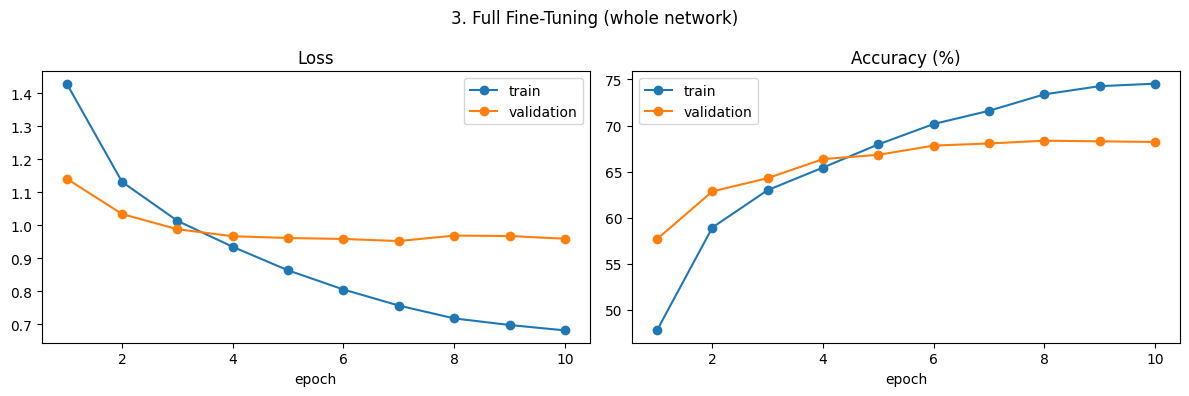

In [16]:
trained["full_finetune"] = run_experiment("full_finetune")
plot_history(trained["full_finetune"][1])

---
## 9. Evaluation on the Test Set
Each model (its best epoch) is evaluated on the **7,178 test images it has never seen**:
- **Accuracy** — % of correct predictions.
- **Loss** — how confident and correct the predictions are (lower = better).
- **Macro-F1** — average F1 over the 7 classes, every class counts equally → shows if rare classes (`disgust`) are ignored.
- **Training time** and **inference speed**.


<div dir="rtl">

## 9. التقييم على بيانات الاختبار
نقيّم كل نموذج (أفضل دورة له) على **7,178 صورة اختبار لم يرها أبداً**:
- **الدقة (Accuracy)** — نسبة التوقعات الصحيحة.
- **الخسارة (Loss)** — مدى صحة التوقعات وثقتها (الأقل أفضل).
- **Macro-F1** — متوسط F1 للأصناف السبعة بالتساوي ← يكشف إن كان النموذج يتجاهل الأصناف النادرة.
- **زمن التدريب** و**سرعة التوقّع**.

</div>

In [17]:
test_results, rows = {}, []
for key, (model, info) in trained.items():
    model.eval()
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    res = run_epoch(model, test_loader)
    if device.type == "cuda":
        torch.cuda.synchronize()
    res["ms_per_image"] = 1000 * (time.time() - t0) / len(test_ds)
    res["weighted_f1"] = 100 * f1_score(res["labels"], res["preds"], average="weighted")
    test_results[key] = res
    rows.append({
        "Strategy": info["name"],
        "Trainable params": f"{info['trainable_params']:,} ({100 * info['trainable_params'] / info['total_params']:.1f}%)",
        "Train time (min)": round(info["train_time_sec"] / 60, 1),
        "Sec / epoch": round(float(np.mean(info["history"]["epoch_time"])), 1),
        "Best epoch": info["best_epoch"],
        "Val acc (%)": round(info["best_val_acc"], 2),
        "Test acc (%)": round(res["acc"], 2),
        "Test loss": round(res["loss"], 4),
        "Test macro-F1 (%)": round(res["macro_f1"], 2),
        "Test weighted-F1 (%)": round(res["weighted_f1"], 2),
        "Inference (ms/img, batched)": round(res["ms_per_image"], 2),
    })

comparison = pd.DataFrame(rows)
comparison.to_csv(f"{OUT_DIR}/comparison.csv", index=False)
comparison.set_index("Strategy").T

eval:   0%|          | 0/113 [00:00<?, ?it/s]

eval:   0%|          | 0/113 [00:00<?, ?it/s]

eval:   0%|          | 0/113 [00:00<?, ?it/s]

Strategy,1. Feature Extraction (last layer only),2. Partial Fine-Tuning (last 2 blocks + last layer),3. Full Fine-Tuning (whole network)
Trainable params,"8,967 (0.2%)","1,138,359 (28.3%)","4,016,515 (100.0%)"
Train time (min),15.7,15.4,18.4
Sec / epoch,94.3,92.2,110.2
Best epoch,9,8,8
Val acc (%),43.35,55.82,68.35
Test acc (%),43.52,54.64,67.75
Test loss,1.4931,1.1916,0.9186
Test macro-F1 (%),38.49,50.32,66.67
Test weighted-F1 (%),42.09,54.12,67.52
"Inference (ms/img, batched)",3.95,2.69,2.61


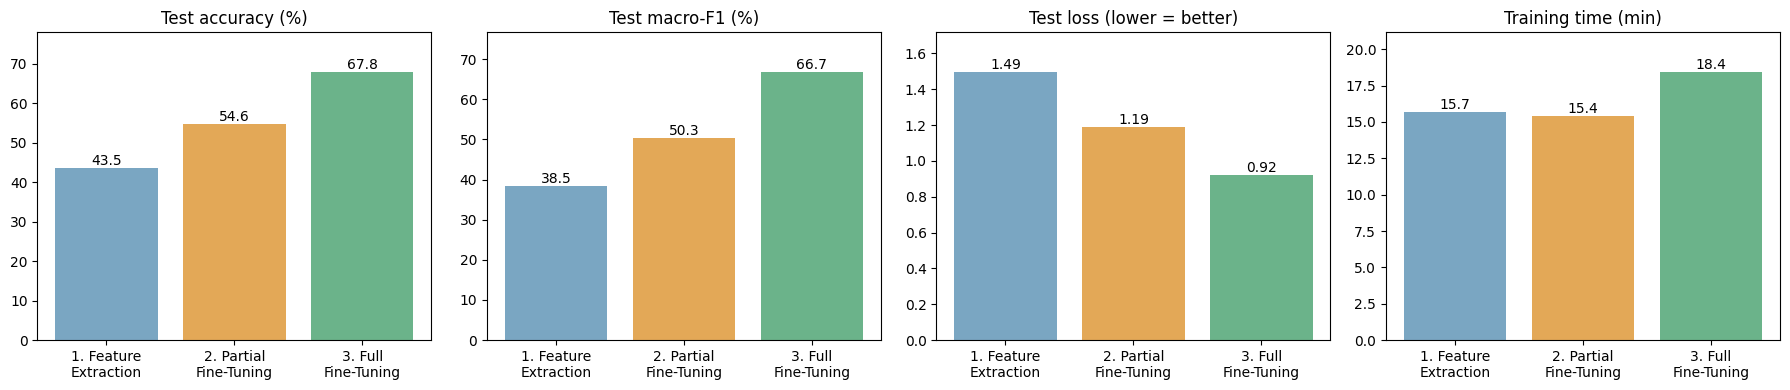

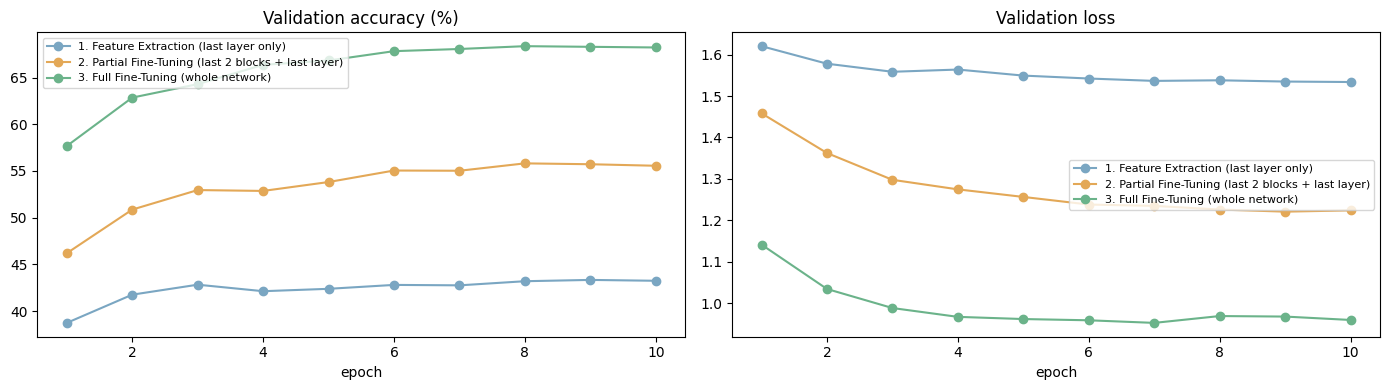

In [18]:
# ---- Visual comparison: accuracy, macro-F1, loss, training time ----
# ---- مقارنة مرئية: الدقة، F1، الخسارة، زمن التدريب ----
short = ["1. Feature\nExtraction", "2. Partial\nFine-Tuning", "3. Full\nFine-Tuning"][:len(comparison)]
colors = ["#7aa6c2", "#e3a857", "#6bb38a"][:len(comparison)]
metrics = [("Test acc (%)", "Test accuracy (%)"), ("Test macro-F1 (%)", "Test macro-F1 (%)"),
           ("Test loss", "Test loss (lower = better)"), ("Train time (min)", "Training time (min)")]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (col, title) in zip(axes, metrics):
    vals = comparison[col].values
    bars = ax.bar(short, vals, color=colors)
    ax.bar_label(bars, fmt="%.2f" if col == "Test loss" else "%.1f")
    ax.set_title(title)
    ax.margins(y=0.15)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_comparison_bars.png", dpi=120)
plt.show()

# ---- Validation curves of the 3 strategies on the same plot ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for (key, (_, info)), c in zip(trained.items(), colors):
    h = info["history"]; ep = range(1, len(h["val_acc"]) + 1)
    ax[0].plot(ep, h["val_acc"], "o-", color=c, label=info["name"])
    ax[1].plot(ep, h["val_loss"], "o-", color=c, label=info["name"])
ax[0].set_title("Validation accuracy (%)"); ax[1].set_title("Validation loss")
for a in ax:
    a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_validation_curves_all.png", dpi=120)
plt.show()

### Per-class results
Overall accuracy hides problems with rare or similar-looking classes, so we look at **F1 per emotion** and the **confusion matrix** (rows = true emotion, columns = predicted emotion, values = % of that true class).


<div dir="rtl">

### النتائج لكل صنف
الدقة الكلية تخفي مشاكل الأصناف النادرة أو المتشابهة، فننظر إلى **F1 لكل شعور** و**مصفوفة الالتباس** (الصفوف = الشعور الحقيقي، الأعمدة = الشعور المتوقَّع، والقيم = نسبة من الصنف الحقيقي).

</div>

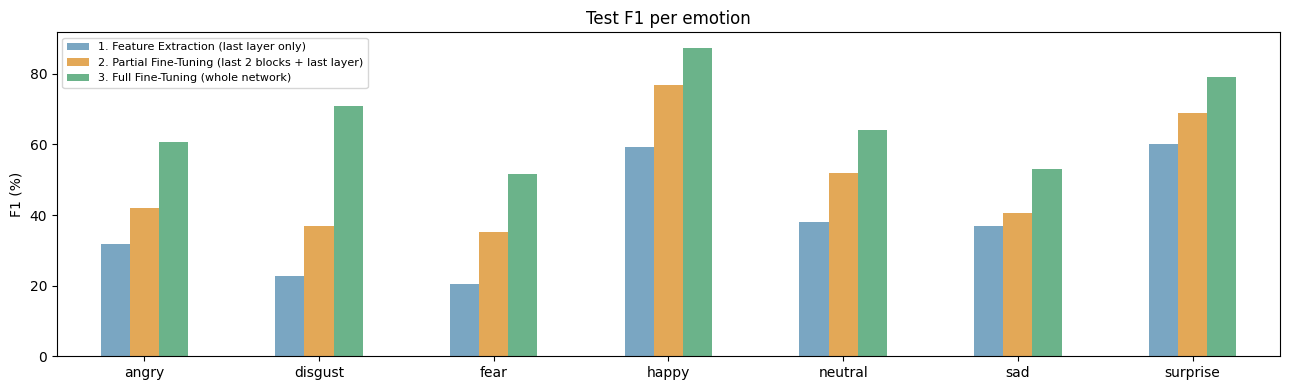

,1. Feature Extraction (last layer only),2. Partial Fine-Tuning (last 2 blocks + last layer),3. Full Fine-Tuning (whole network)
angry,31.7,42.1,60.7
disgust,22.8,36.9,70.9
fear,20.6,35.2,51.5
happy,59.3,76.9,87.4
neutral,38.1,51.8,64.1
sad,36.9,40.6,53.1
surprise,60.0,68.8,79.0


In [19]:
# ---- F1 per emotion for each strategy ----
per_class = {}
for key, res in test_results.items():
    per_class[STRATEGIES[key]] = f1_score(res["labels"], res["preds"], average=None) * 100
per_class_df = pd.DataFrame(per_class, index=CLASS_NAMES).round(1)
per_class_df.to_csv(f"{OUT_DIR}/per_class_f1.csv")

ax = per_class_df.plot(kind="bar", figsize=(13, 4), color=colors, rot=0)
ax.set_ylabel("F1 (%)"); ax.set_title("Test F1 per emotion"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_per_class_f1.png", dpi=120)
plt.show()
per_class_df

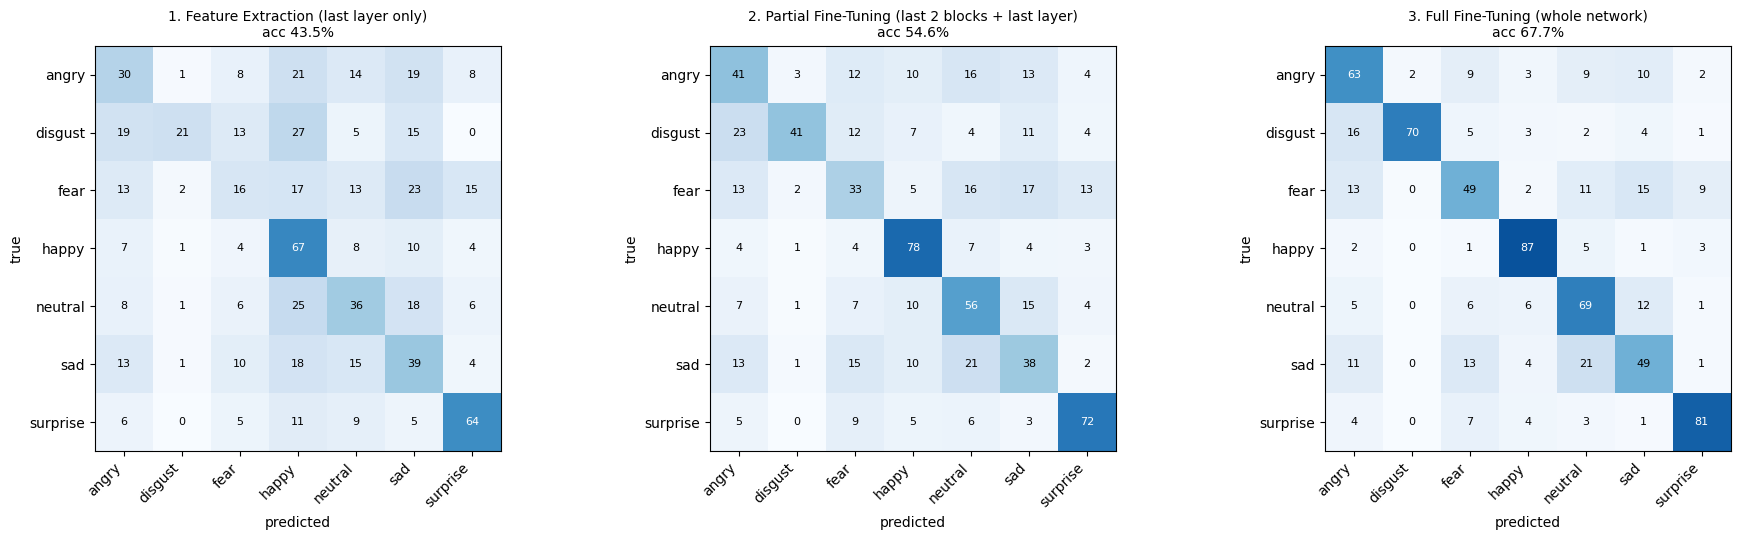

In [20]:
# ---- Normalised confusion matrices / مصفوفات الالتباس ----
fig, axes = plt.subplots(1, len(test_results), figsize=(6.2 * len(test_results), 5.5))
axes = np.atleast_1d(axes)
for ax, (key, res) in zip(axes, test_results.items()):
    cm = confusion_matrix(res["labels"], res["preds"], labels=range(NUM_CLASSES))
    cm_pct = 100 * cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{cm_pct[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if cm_pct[i, j] > 55 else "black")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{STRATEGIES[key]}\nacc {res['acc']:.1f}%", fontsize=10)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07_confusion_matrices.png", dpi=120)
plt.show()

---
## 10. Best Model — Detailed Report, Successes & Failures
We choose the best strategy by **validation accuracy** (not test accuracy — choosing on the test set would be cheating), then inspect it in detail.


<div dir="rtl">

## 10. أفضل نموذج — تقرير مفصّل وأمثلة نجاح وفشل
نختار أفضل استراتيجية حسب **دقة التحقق** (وليس دقة الاختبار — الاختيار على بيانات الاختبار يعتبر غشاً)، ثم نفحصه بالتفصيل.

</div>

In [21]:
BEST = max(trained, key=lambda k: trained[k][1]["best_val_acc"])
best_model, best_info = trained[BEST]
best_res = test_results[BEST]
shutil.copy(f"{MODELS_DIR}/{BEST}.pth", f"{MODELS_DIR}/best_model.pth")
print(f"🏆 Best strategy: {STRATEGIES[BEST]}")
print(f"   val acc {best_info['best_val_acc']:.2f}% | test acc {best_res['acc']:.2f}% | test macro-F1 {best_res['macro_f1']:.2f}%\n")
report = classification_report(best_res["labels"], best_res["preds"], target_names=CLASS_NAMES, digits=3, zero_division=0)
print(report)
open(f"{OUT_DIR}/best_model_classification_report.txt", "w").write(f"{STRATEGIES[BEST]}\n\n{report}")

# Most frequent confusions / أكثر الأخطاء تكراراً
cm = confusion_matrix(best_res["labels"], best_res["preds"], labels=range(NUM_CLASSES))
pairs = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
print("Top-5 confusions (true -> predicted):")
for cnt, t, p in sorted(pairs, reverse=True)[:5]:
    print(f"   {t:>9} -> {p:<9} {cnt} images")

🏆 Best strategy: 3. Full Fine-Tuning (whole network)
   val acc 68.35% | test acc 67.75% | test macro-F1 66.67%

              precision    recall  f1-score   support

       angry      0.585     0.630     0.607       958
     disgust      0.716     0.703     0.709       111
        fear      0.542     0.490     0.515      1024
       happy      0.879     0.868     0.874      1774
     neutral      0.597     0.692     0.641      1233
         sad      0.582     0.489     0.531      1247
    surprise      0.768     0.813     0.790       831

    accuracy                          0.677      7178
   macro avg      0.667     0.669     0.667      7178
weighted avg      0.676     0.677     0.675      7178

Top-5 confusions (true -> predicted):
         sad -> neutral   260 images
         sad -> fear      166 images
        fear -> sad       156 images
     neutral -> sad       147 images
         sad -> angry     139 images


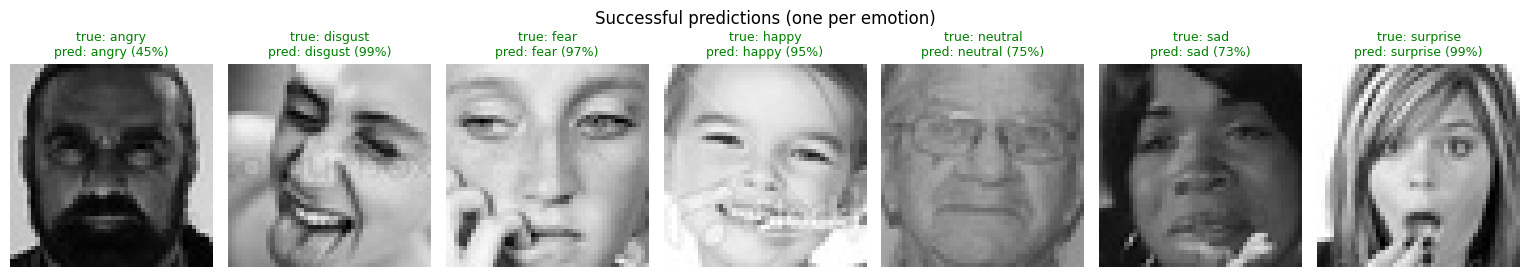

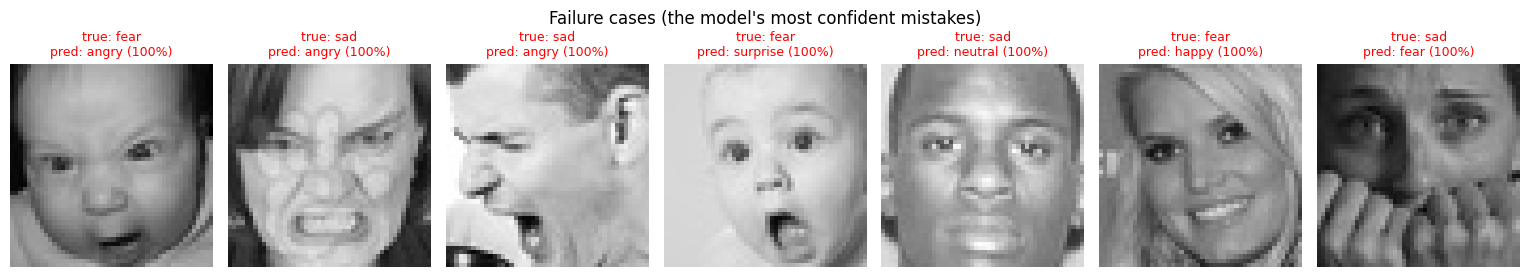

In [22]:
# ---- Successful vs failed predictions / توقعات ناجحة وأخرى فاشلة ----
rng = np.random.default_rng(SEED)
conf = best_res["probs"].max(1)
correct_idx = np.where(best_res["preds"] == best_res["labels"])[0]
wrong_idx   = np.where(best_res["preds"] != best_res["labels"])[0]
# successes: one random correct prediction per emotion; failures: the most confident mistakes
succ = [rng.choice(correct_idx[best_res["labels"][correct_idx] == c]) for c in range(NUM_CLASSES)
        if (best_res["labels"][correct_idx] == c).any()][:7]
fail = wrong_idx[np.argsort(-conf[wrong_idx])][:7]

def show_cases(idxs, title, color, fname):
    plt.figure(figsize=(2.2 * len(idxs), 2.9))
    for k, i in enumerate(idxs):
        img, _ = raw_test[i]
        plt.subplot(1, len(idxs), k + 1)
        plt.imshow(img, cmap="gray"); plt.axis("off")
        plt.title(f"true: {CLASS_NAMES[best_res['labels'][i]]}\npred: {CLASS_NAMES[best_res['preds'][i]]} "
                  f"({100 * conf[i]:.0f}%)", fontsize=9, color=color)
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{fname}", dpi=120); plt.show()

show_cases(succ, "Successful predictions (one per emotion)", "green", "08_success_cases.png")
show_cases(fail, "Failure cases (the model's most confident mistakes)", "red", "09_failure_cases.png")

### Why does the model fail? How could it be improved?
**Typical failure reasons on FER2013:**
- Similar expressions: *fear ↔ surprise* (open mouth/eyes), *sad ↔ neutral*, *angry ↔ disgust*.
- Low resolution (48×48), occlusion (hands, glasses), side poses and **noisy labels** (some images are mislabeled or not faces).
- Very few `disgust` examples.

**Improvements:**
1. **Better data:** use the cleaned **FER+** labels, collect more `disgust` images, or oversample rare classes.
2. **Face alignment** (rotate/crop faces using eye landmarks) before classification.
3. **Stronger augmentation:** Random Erasing, MixUp/CutMix; **label smoothing** for noisy labels.
4. **Longer training / tuning:** more epochs, gradual unfreezing, learning-rate search.
5. **Bigger or face-specific backbones:** EfficientNet-B2, ConvNeXt, ViT, or models pretrained on face datasets (e.g. VGGFace2).
6. **Test-Time Augmentation** and **ensembles** of the 3 strategies.


<div dir="rtl">

### لماذا يخطئ النموذج؟ وكيف نحسّنه؟
**أسباب الخطأ الشائعة في FER2013:**
- تعابير متشابهة: *الخوف ↔ المفاجأة* (فم وعيون مفتوحة)، *الحزن ↔ المحايد*، *الغضب ↔ الاشمئزاز*.
- دقة منخفضة (48×48)، وأشياء تغطي الوجه (أيدٍ، نظارات)، ووضعيات جانبية، و**تسميات خاطئة** في البيانات.
- قلة صور `disgust` جداً.

**طرق التحسين:**
1. **بيانات أفضل:** استخدام تسميات **FER+** المنقّحة، أو جمع صور أكثر للاشمئزاز، أو مضاعفة الأصناف النادرة.
2. **محاذاة الوجه** (تدويره وقصّه حسب موضع العينين) قبل التصنيف.
3. **توسيع أقوى:** Random Erasing وMixUp/CutMix، و**Label Smoothing** لتخفيف أثر التسميات الخاطئة.
4. **تدريب أطول وضبط أفضل:** دورات أكثر، فك تجميد تدريجي، والبحث عن أفضل معدل تعلّم.
5. **نماذج أكبر أو مخصصة للوجوه:** EfficientNet-B2 أو ConvNeXt أو ViT، أو نماذج مدرّبة مسبقاً على وجوه.
6. **التوسيع وقت الاختبار (TTA)** و**دمج النماذج الثلاثة**.

</div>

---
## 11. Real Application: Face Detection → Emotion Prediction
In a real photo the face is only a small part of the image. A complete system therefore works in two stages:
1. **Detect the face** with OpenCV (Haar cascade on OpenCV 4, YuNet DNN detector on OpenCV 5).
2. **Crop → grayscale → resize → normalise → model → emotion + confidence** (the same preprocessing as training).


<div dir="rtl">

## 11. تطبيق حقيقي: اكتشاف الوجه ← توقّع الشعور
في الصورة الحقيقية يكون الوجه جزءاً صغيراً منها، لذلك يعمل النظام الكامل على مرحلتين:
1. **اكتشاف الوجه** بمكتبة OpenCV (كاشف Haar في الإصدار 4، وكاشف YuNet في الإصدار 5).
2. **قص الوجه ← تحويله لرمادي ← تغيير الحجم ← التطبيع ← النموذج ← الشعور ونسبة الثقة** (نفس معالجة التدريب).

</div>

Face detector: Haar cascade (OpenCV 4.14.0 )


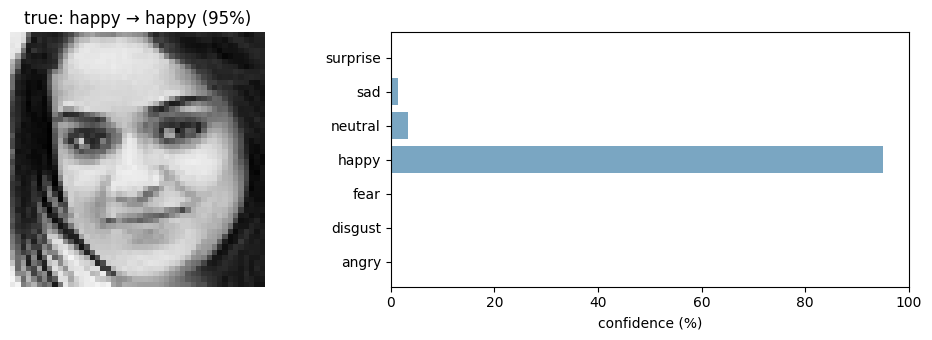

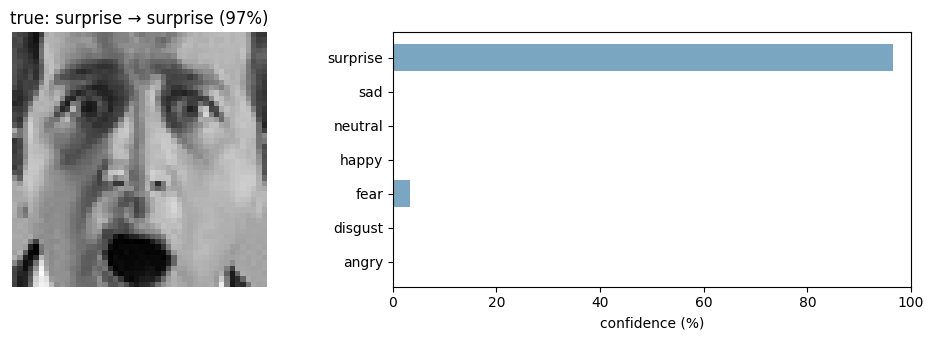

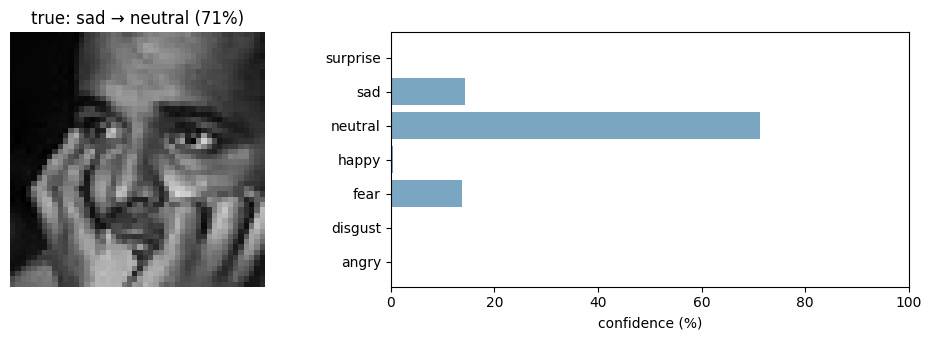

In [23]:
import cv2
from PIL import Image

import urllib.request

def make_face_detector():
    """Returns a function gray_image -> list of face boxes (x, y, w, h).
    OpenCV 4.x: Haar cascade (built in). OpenCV 5.x removed it -> YuNet DNN face detector."""
    try:
        if hasattr(cv2, "CascadeClassifier"):
            casc = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
            print("Face detector: Haar cascade (OpenCV", cv2.__version__, ")")
            return lambda g: [tuple(int(v) for v in f) for f in
                              casc.detectMultiScale(g, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))]
        path = "face_detection_yunet_2023mar.onnx"
        if not os.path.exists(path):
            urllib.request.urlretrieve("https://github.com/opencv/opencv_zoo/raw/main/models/"
                                       "face_detection_yunet/face_detection_yunet_2023mar.onnx", path)
        yunet = cv2.FaceDetectorYN.create(path, "", (320, 320), 0.8)
        def detect(g):
            yunet.setInputSize((g.shape[1], g.shape[0]))
            _, faces = yunet.detect(cv2.cvtColor(g, cv2.COLOR_GRAY2BGR))
            return [] if faces is None else [tuple(int(v) for v in f[:4]) for f in faces]
        print("Face detector: YuNet (OpenCV", cv2.__version__, ")")
        return detect
    except Exception as e:
        print("No face detector available -> the whole image is used as the face.", type(e).__name__)
        return lambda g: []

detect_faces = make_face_detector()
best_model.eval()

def torch_probs(x):
    with torch.no_grad():
        return torch.softmax(best_model(x.to(device)), 1)[0].cpu().numpy()

def predict_emotion(pil_img, probs_fn=torch_probs):
    """Full pipeline: image -> (largest) face -> emotion. Returns (label, probs, box).
    المسار الكامل: صورة ← أكبر وجه ← الشعور."""
    gray = np.array(pil_img.convert("L"))
    faces = detect_faces(gray)
    if faces:
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
        x, y = max(x, 0), max(y, 0)
        m = int(0.1 * w)                                  # small margin around the face
        x0, y0 = max(x - m, 0), max(y - m, 0)
        face = Image.fromarray(gray[y0:y + h + m, x0:x + w + m])
        box = tuple(int(v) for v in (x0, y0, x + w + m, y + h + m))
    else:                                                 # no face found -> use whole image
        face, box = Image.fromarray(gray), None
    probs = probs_fn(eval_tf(face).unsqueeze(0))
    return CLASS_NAMES[int(probs.argmax())], probs, box

def show_prediction(pil_img, title=""):
    label, probs, box = predict_emotion(pil_img)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1, 1.4]})
    ax[0].imshow(pil_img.convert("RGB")); ax[0].axis("off")
    if box:
        ax[0].add_patch(plt.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, color="lime", lw=2))
    ax[0].set_title(f"{title} → {label} ({100 * probs.max():.0f}%)")
    ax[1].barh(CLASS_NAMES, probs * 100, color="#7aa6c2"); ax[1].set_xlim(0, 100); ax[1].set_xlabel("confidence (%)")
    plt.tight_layout(); plt.show()

# Demo on a few test images (one per emotion) / تجربة على صور من بيانات الاختبار
test_targets = np.array(raw_test.targets)
for c in [3, 6, 5]:   # happy, surprise, sad
    i = int(rng.choice(np.where(test_targets == c)[0]))
    show_prediction(raw_test[i][0], f"true: {CLASS_NAMES[c]}")

### Try it with your own photo
Set `TRY_MY_PHOTO = True` in the next cell, run it and upload any photo with a face (Colab only).


<div dir="rtl">

### جرّبه بصورتك
غيّر `TRY_MY_PHOTO = True` في الخلية التالية ثم شغّلها وارفع أي صورة فيها وجه (في Colab فقط).

</div>

In [24]:
TRY_MY_PHOTO = False   # set to True and run this cell to upload a photo (kept False so "Run all" doesn't stop here)
if TRY_MY_PHOTO:
    try:
        from google.colab import files
        uploaded = files.upload()
        for fname in uploaded:
            show_prediction(Image.open(fname), fname)
    except ImportError:
        print("Not running in Colab — use show_prediction(Image.open('your_photo.jpg')) instead.")

---
## 12. Optimization: ONNX Export + INT8 Quantization
- **ONNX** is a standard model format that runs without PyTorch (servers, mobile, web, edge devices) using **ONNX Runtime**.
- **Quantization** stores weights/activations as 8-bit integers instead of 32-bit floats → a **smaller** file and usually **faster CPU inference**, with a small accuracy cost. We use **static INT8 quantization** calibrated on validation images.

We compare PyTorch vs ONNX FP32 vs ONNX INT8 on **CPU** (where deployed models usually run): file size, speed and accuracy on a test subset.


<div dir="rtl">

## 12. التحسين: التصدير إلى ONNX والتكميم INT8
- **ONNX** صيغة قياسية للنماذج تعمل بدون PyTorch (خوادم، جوال، ويب، أجهزة طرفية) عبر **ONNX Runtime**.
- **التكميم (Quantization)** يخزّن الأوزان بأعداد صحيحة 8-بت بدلاً من 32-بت ← ملف **أصغر** وتوقّع **أسرع** على المعالج غالباً، مع خسارة بسيطة في الدقة. نستخدم **التكميم الثابت INT8** مع معايرة على صور التحقق.

نقارن PyTorch و ONNX FP32 و ONNX INT8 على **المعالج (CPU)**: حجم الملف، والسرعة، والدقة على جزء من بيانات الاختبار.

</div>

In [25]:
import onnx, onnxruntime as ort

ONNX_FP32 = f"{MODELS_DIR}/fer_efficientnet_b0_fp32.onnx"
ONNX_INT8 = f"{MODELS_DIR}/fer_efficientnet_b0_int8.onnx"

cpu_model = copy.deepcopy(best_model).float().cpu().eval()
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
export_args = dict(input_names=["image"], output_names=["logits"], opset_version=17,
                   dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}})
try:
    torch.onnx.export(cpu_model, dummy, ONNX_FP32, dynamo=False, **export_args)   # classic exporter
except Exception as e:
    print("Classic exporter unavailable, using the new one:", type(e).__name__)
    torch.onnx.export(cpu_model, (dummy,), ONNX_FP32, dynamo=True, **export_args)
onnx.checker.check_model(onnx.load(ONNX_FP32))

# Check ONNX gives the same output as PyTorch / نتأكد أن ONNX يعطي نفس نتيجة PyTorch
sess_fp32 = ort.InferenceSession(ONNX_FP32, providers=["CPUExecutionProvider"])
x = eval_tf(raw_test[0][0]).unsqueeze(0)
with torch.no_grad():
    torch_out = cpu_model(x).numpy()
onnx_out = sess_fp32.run(None, {"image": x.numpy()})[0]
print(f"✅ ONNX exported | max difference vs PyTorch: {np.abs(torch_out - onnx_out).max():.6f}")

/tmp/ipykernel_469/1265927807.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(cpu_model, dummy, ONNX_FP32, dynamo=False, **export_args)   # classic exporter


✅ ONNX exported | max difference vs PyTorch: 0.000016


In [26]:
from onnxruntime.quantization import (quantize_static, CalibrationDataReader,
                                      QuantType, QuantFormat)

class CalibReader(CalibrationDataReader):
    """Feeds ~300 validation images to measure activation ranges for INT8."""
    def __init__(self, n_images=300):
        idx = np.random.default_rng(SEED).choice(len(val_ds), size=min(n_images, len(val_ds)), replace=False)
        self.batches = iter([val_ds[int(i)][0].unsqueeze(0).numpy() for i in idx])
    def get_next(self):
        b = next(self.batches, None)
        return None if b is None else {"image": b}

src = ONNX_FP32
try:   # optional graph pre-processing recommended by ONNX Runtime
    from onnxruntime.quantization.shape_inference import quant_pre_process
    quant_pre_process(ONNX_FP32, f"{MODELS_DIR}/_prep.onnx")
    src = f"{MODELS_DIR}/_prep.onnx"
except Exception as e:
    print("pre-processing skipped:", type(e).__name__)

quantize_static(src, ONNX_INT8, CalibReader(), quant_format=QuantFormat.QDQ, per_channel=True,
                activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
if os.path.exists(f"{MODELS_DIR}/_prep.onnx"):
    os.remove(f"{MODELS_DIR}/_prep.onnx")
sess_int8 = ort.InferenceSession(ONNX_INT8, providers=["CPUExecutionProvider"])
print("✅ INT8 model saved:", ONNX_INT8)

✅ INT8 model saved: fer_project_outputs/models/fer_efficientnet_b0_int8.onnx


In [27]:
# ---- Compare size, CPU speed and accuracy / مقارنة الحجم والسرعة والدقة ----
N_EVAL = 1000   # test subset evaluated on CPU (full test set on CPU is slow)
sub_idx = np.random.default_rng(SEED).choice(len(test_ds), size=min(N_EVAL, len(test_ds)), replace=False)
X_sub = np.stack([test_ds[int(i)][0].numpy() for i in sub_idx])
y_sub = np.array([test_ds.targets[int(i)] for i in sub_idx])

def eval_backend(fn, bs=32):
    preds = np.concatenate([fn(X_sub[i:i + bs]).argmax(1) for i in range(0, len(X_sub), bs)])
    single = X_sub[:1]
    for _ in range(5): fn(single)                      # warm-up
    t0 = time.time()
    for _ in range(50): fn(single)
    return 100 * (preds == y_sub).mean(), 1000 * (time.time() - t0) / 50

torch.set_num_threads(os.cpu_count())
def torch_fn(a):
    with torch.no_grad():
        return cpu_model(torch.from_numpy(a)).numpy()
backends = {
    "PyTorch FP32 (CPU)": (torch_fn, f"{MODELS_DIR}/best_model.pth"),
    "ONNX FP32 (CPU)":    (lambda a: sess_fp32.run(None, {"image": a})[0], ONNX_FP32),
    "ONNX INT8 (CPU)":    (lambda a: sess_int8.run(None, {"image": a})[0], ONNX_INT8),
}
opt_rows = []
for name, (fn, path) in backends.items():
    acc, ms = eval_backend(fn)
    opt_rows.append({"Model": name, "File size (MB)": round(os.path.getsize(path) / 1e6, 1),
                     f"Accuracy on {len(X_sub)} test imgs (%)": round(acc, 2),
                     "Latency (ms / image, CPU)": round(ms, 1)})
optimization = pd.DataFrame(opt_rows)
optimization.to_csv(f"{OUT_DIR}/optimization.csv", index=False)
optimization

,Model,File size (MB),Accuracy on 1000 test imgs (%),"Latency (ms / image, CPU)"
0,PyTorch FP32 (CPU),16.3,66.7,95.1
1,ONNX FP32 (CPU),16.1,66.7,24.1
2,ONNX INT8 (CPU),4.9,29.9,21.2


### Demo app (Gradio)
A small web app that uses the **quantized ONNX model** — upload a photo or use the webcam. `share=True` gives a public link for ~72 hours.


<div dir="rtl">

### تطبيق العرض (Gradio)
تطبيق ويب صغير يستخدم **نموذج ONNX المكمَّم** — ارفع صورة أو استخدم الكاميرا. الخيار `share=True` يعطي رابطاً عاماً لمدة 72 ساعة تقريباً.

</div>

In [28]:
import gradio as gr

def int8_probs(x):
    logits = sess_int8.run(None, {"image": x.numpy()})[0][0]
    e = np.exp(logits - logits.max())
    return e / e.sum()

def app_fn(img):
    if img is None:
        return {}, None
    pil = Image.fromarray(img)
    label, probs, box = predict_emotion(pil, probs_fn=int8_probs)
    out = np.array(pil.convert("RGB")).copy()
    if box:
        cv2.rectangle(out, box[:2], box[2:], (0, 255, 0), 3)
        cv2.putText(out, label, (box[0], max(box[1] - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    return {CLASS_NAMES[i]: float(p) for i, p in enumerate(probs)}, out

demo = gr.Interface(
    fn=app_fn,
    inputs=gr.Image(sources=["upload", "webcam"], type="numpy", label="Face photo"),
    outputs=[gr.Label(num_top_classes=3, label="Emotion"), gr.Image(label="Detected face")],
    title="Facial Emotion Recognition (EfficientNet-B0, ONNX INT8)",
    description="Upload a photo or use your webcam. The face is detected, then its emotion is predicted.",
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7eca239124ecbf913c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [30]:
# ===== 12b. Fixing the INT8 problem + final deployed model =====
# Why did INT8 fail (accuracy dropped to ~30%)? EfficientNet uses DEPTHWISE convolutions
# (one small filter per channel). Their weights are very sensitive to 8-bit rounding.
# لماذا فشل INT8؟ طبقات الالتفاف العميقة (Depthwise) في EfficientNet حساسة جداً للتقريب إلى 8-بت.
!pip install -q onnxconverter-common
import onnx
import gradio as gr
from onnxconverter_common import float16
from onnxruntime.quantization import quantize_dynamic

# Option A — FP16: 16-bit floats instead of 32-bit -> half the size, (almost) no accuracy loss
# الخيار أ — FP16: نصف الحجم تقريباً بدون خسارة في الدقة
ONNX_FP16 = f"{MODELS_DIR}/fer_efficientnet_b0_fp16.onnx"
onnx.save(float16.convert_float_to_float16(onnx.load(ONNX_FP32), keep_io_types=True), ONNX_FP16)
sess_fp16 = ort.InferenceSession(ONNX_FP16, providers=["CPUExecutionProvider"])

# Option B — INT8 but keep the sensitive depthwise convolutions (and the first conv) in FP32
# الخيار ب — INT8 مع إبقاء طبقات Depthwise الحساسة بدقة كاملة
graph = onnx.load(ONNX_FP32).graph
convs = [n.name for n in graph.node if n.op_type == "Conv"]
depthwise = [n.name for n in graph.node if n.op_type == "Conv"
             and any(a.name == "group" and a.i > 1 for a in n.attribute)]
print(f"{len(convs)} conv layers, {len(depthwise)} of them depthwise (kept in FP32)")
ONNX_INT8_PARTIAL = f"{MODELS_DIR}/fer_efficientnet_b0_int8_partial.onnx"
quantize_dynamic(ONNX_FP32, ONNX_INT8_PARTIAL, weight_type=QuantType.QInt8, per_channel=True,
                 nodes_to_exclude=depthwise + convs[:1])
sess_int8_partial = ort.InferenceSession(ONNX_INT8_PARTIAL, providers=["CPUExecutionProvider"])

new_rows = []
for name, sess, path in [("ONNX FP16 (CPU)", sess_fp16, ONNX_FP16),
                         ("ONNX INT8 partial (CPU)", sess_int8_partial, ONNX_INT8_PARTIAL)]:
    acc, ms = eval_backend(lambda a, s=sess: s.run(None, {"image": a})[0])
    new_rows.append({"Model": name, "File size (MB)": round(os.path.getsize(path) / 1e6, 1),
                     f"Accuracy on {len(X_sub)} test imgs (%)": round(acc, 2),
                     "Latency (ms / image, CPU)": round(ms, 1)})
optimization = pd.concat([optimization, pd.DataFrame(new_rows)], ignore_index=True)
optimization.to_csv(f"{OUT_DIR}/optimization.csv", index=False)
display(optimization)

# ---- Re-launch the demo app with the FP16 model (same accuracy as FP32, half the size) ----
# ---- إعادة تشغيل تطبيق العرض بنموذج FP16 ----
def fp16_probs(x):
    logits = sess_fp16.run(None, {"image": x.numpy()})[0][0]
    e = np.exp(logits - logits.max())
    return e / e.sum()

def app_fn_fp16(img):
    if img is None:
        return {}, None
    pil = Image.fromarray(img)
    label, probs, box = predict_emotion(pil, probs_fn=fp16_probs)
    out = np.array(pil.convert("RGB")).copy()
    if box:
        cv2.rectangle(out, box[:2], box[2:], (0, 255, 0), 3)
        cv2.putText(out, label, (box[0], max(box[1] - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    return {CLASS_NAMES[i]: float(p) for i, p in enumerate(probs)}, out

demo_fp16 = gr.Interface(
    fn=app_fn_fp16,
    inputs=gr.Image(sources=["upload", "webcam"], type="numpy", label="Face photo"),
    outputs=[gr.Label(num_top_classes=3, label="Emotion"), gr.Image(label="Detected face")],
    title="Facial Emotion Recognition (EfficientNet-B0, ONNX FP16)",
    description="Upload a photo or use your webcam. The face is detected, then its emotion is predicted.",
)
demo_fp16.launch(share=True, debug=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.5/89.5 kB 4.0 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -8.61218936165642e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -6.944801356212338e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 2.2658328546754092e-08 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 3.250497826456922e-08 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -2.0008252832326434e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 5.7563685373906

81 conv layers, 16 of them depthwise (kept in FP32)


,Model,File size (MB),Accuracy on 1000 test imgs (%),"Latency (ms / image, CPU)"
0,PyTorch FP32 (CPU),16.3,66.7,95.1
1,ONNX FP32 (CPU),16.1,66.7,24.1
2,ONNX INT8 (CPU),4.9,29.9,21.2
3,ONNX FP16 (CPU),8.1,66.8,18.2
4,ONNX INT8 partial (CPU),4.9,64.3,118.5


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f1d4dc702981f5e717.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
## 13. Summary & Download the Outputs
The cell below prints the final summary and downloads a **zip** with the models, figures and result tables — these go to the GitHub repository together with this notebook and the README.


<div dir="rtl">

## 13. الملخص وتنزيل المخرجات
الخلية التالية تطبع الملخص النهائي وتنزّل ملف **zip** فيه النماذج والرسوم وجداول النتائج — هذه ترفع على GitHub مع هذا الدفتر وملف README.

</div>

In [31]:
summary = {
    "best_strategy": STRATEGIES[BEST],
    "comparison": comparison.to_dict(orient="records"),
    "per_class_f1": per_class_df.to_dict(),
    "optimization": optimization.to_dict(orient="records"),
    "settings": {"img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "epochs": NUM_EPOCHS,
                 "lr_head": LR_HEAD, "lr_backbone": LR_BACKBONE, "val_split": VAL_SPLIT,
                 "class_weights": class_weights.numpy().round(3).tolist(),
                 "train/val/test": [len(train_ds), len(val_ds), len(test_ds)],
                 "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
                 "torch": torch.__version__},
}
json.dump(summary, open(f"{OUT_DIR}/results_summary.json", "w"), indent=2, default=float)
print(comparison[["Strategy", "Test acc (%)", "Test loss", "Test macro-F1 (%)", "Train time (min)"]].to_string(index=False))
print("\n🏆 Best:", STRATEGIES[BEST])

# Zip everything except the per-strategy .pth files (best_model.pth is kept)
zip_dir = "fer_project_zip"
shutil.rmtree(zip_dir, ignore_errors=True)
shutil.copytree(OUT_DIR, zip_dir, ignore=lambda d, f: [x for x in f if x.endswith(".pth") and x != "best_model.pth"])
shutil.make_archive("fer_project_outputs", "zip", zip_dir)
print("Saved fer_project_outputs.zip")
try:
    from google.colab import files
    files.download("fer_project_outputs.zip")
except ImportError:
    pass

                                           Strategy  Test acc (%)  Test loss  Test macro-F1 (%)  Train time (min)
            1. Feature Extraction (last layer only)         43.52     1.4931              38.49              15.7
2. Partial Fine-Tuning (last 2 blocks + last layer)         54.64     1.1916              50.32              15.4
                3. Full Fine-Tuning (whole network)         67.75     0.9186              66.67              18.4

🏆 Best: 3. Full Fine-Tuning (whole network)
Saved fer_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>